# Learner

> fastai Learners for spectral models

In [ ]:
#| default_exp learner

In [ ]:
#| export
from fastcore.all import *
from fastai.learner import Learner, Recorder
from fastai.torch_core import params
from fastai.losses import MSELossFlat
from fastai.metrics import R2Score
from fastai.callback.core import Callback
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from soilspecdl.dataloader import get_spectral_dls, get_kfold_splitters

/Users/franckalbinet/aai-ws/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [ ]:
from fastcore.test import *
from fastai.callback.schedule import *
from soilspecdl.datasets import load_toy_kssl
from soilspecdl.models import SpectralCNN
from soilspecdl.transforms import BatchSNV

A spectral model has two parts. The `backbone` turns each spectrum into a vector of features. The `head` maps those features to the prediction. `SpectralCNN` and its configurations, such as `MirzaiCNN`, follow this layout.

Fine-tuning a pretrained backbone treats the two parts differently. The head is new and trains first, while the backbone stays fixed. The backbone then adapts with a lower learning rate. fastai does both through parameter groups: `Learner.freeze` freezes every group except the last, and a `slice` of learning rates spreads them across the groups, lowest first. fastai's default `Learner` puts all parameters in one group, so it can do neither.

In [ ]:
#| export
def spectral_splitter(
    m, # Model with `backbone` and `head` attributes
)->list: # Parameter groups: backbone, then head
    "Split a spectral model's parameters into backbone and head groups"
    return L(m.backbone, m.head).map(params)

For the default `SpectralCNN`, the head holds the 257 parameters of `Linear(256, 1)`. The backbone holds the rest:

In [ ]:
model = SpectralCNN()
groups = spectral_splitter(model)
n_params = [sum(p.numel() for p in g) for g in groups]
test_eq(n_params[1], 257)
n_params

[131600, 257]

`spectral_learner` builds a `Learner` with `spectral_splitter`. Its defaults suit regression: mean squared error as the loss and R² as the metric. Pass `loss_func` and `metrics` for other tasks, such as classification.

In [ ]:
#| export
@delegates(Learner.__init__)
def spectral_learner(
    dls, # DataLoaders, e.g. from `get_spectral_dls`
    model, # Model with `backbone` and `head`, e.g. `SpectralCNN()`
    loss_func=None, # Loss function; `MSELossFlat()` if None
    metrics=None, # Metrics; `R2Score()` if None
    splitter=spectral_splitter, # Function splitting the model's parameters into groups
    **kwargs
)->Learner:
    "`Learner` for a spectral model, with backbone and head parameter groups"
    return Learner(dls, model, loss_func=ifnone(loss_func, MSELossFlat()), metrics=ifnone(metrics, R2Score()),
        splitter=splitter, **kwargs)

The examples train on the toy dataset from `soilspecdl.datasets`, predicting exchangeable potassium (Kex) from 500 KSSL MIR spectra:

In [ ]:
toy = load_toy_kssl()
X, y, ids = toy.xy('k.ext_usda.a725_cmolc.kg')
dls, test_idx = get_spectral_dls(X, y.flatten(), toy.wavenumbers, batch_tfms=[BatchSNV()])

The optimizer has one parameter group for the backbone and one for the head:

In [ ]:
learn = spectral_learner(dls, SpectralCNN())
learn.create_opt()
test_eq(len(learn.opt.param_groups), 2)
len(learn.opt.param_groups)

2

`freeze` stops training of the backbone. Following fastai's default `train_bn=True`, the backbone's normalization layers still train, so the head and the `BatchNorm` weights are the only trainable parameters:

In [ ]:
def n_trainable(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

learn.freeze()
test_eq(n_trainable(learn.model.head), 257)
n_trainable(learn.model.backbone), n_trainable(learn.model.head)

(992, 257)

Train the head first, with the backbone frozen. One epoch at each stage shows the steps, not a trained model:

In [ ]:
learn.fit_one_cycle(1, lr_max=1e-3)

epoch     train_loss  valid_loss  r2_score  time    
0         0.736343    0.248580    -0.012090 00:00     


Then unfreeze, and train the whole model with a `slice` of learning rates. The backbone gets the lower rate and the head the higher one:

In [ ]:
learn.unfreeze()
learn.opt.set_hyper('lr', slice(1e-5, 1e-3))
lrs = [h['lr'] for h in learn.opt.hypers]
test_close(lrs, [1e-5, 1e-3])
lrs

[1e-05, 0.001]

In [ ]:
learn.fit_one_cycle(1, lr_max=slice(1e-5, 1e-3))

epoch     train_loss  valid_loss  r2_score  time    
0         0.624940    0.249138    -0.014361 00:00     


## Cross-validation

Cross-validation chooses a training schedule, such as the number of epochs, without touching the test set. `cross_validate` trains one model per fold from `get_kfold_splitters`, and returns each fold's losses and metrics after every epoch.

fastai's `Recorder` keeps the values of the latest `fit` call only. A fine-tuning schedule makes two calls: one with the backbone frozen, one after unfreezing. `_EpochLog` records every epoch across all calls:

In [ ]:
#| export
class _EpochLog(Callback):
    "Record the losses and metrics of every epoch across all `fit` calls, with the call's index as `stage`"
    order = Recorder.order + 1
    def __init__(self): self.rows,self.stage = [],-1
    def before_fit(self): self.stage += 1
    def after_epoch(self): self.rows.append(dict(stage=self.stage, **dict(zip(self.recorder.metric_names[1:], self.learn.final_record))))

In [ ]:
#| export
@delegates(spectral_learner)
def cross_validate(
    X, # Spectral data matrix
    y, # Target values
    wns, # Wavenumbers
    model_fn, # Function returning a fresh model, called once per fold
    fit, # Function training a fold's `Learner`
    n_splits=5, # Number of folds
    seed=42, # Random seed for the fold shuffle
    bs=32, # Batch size
    batch_tfms=None, # Batch transforms, e.g. [BatchSNV()]
    **kwargs
)->pd.DataFrame: # One row per fold and epoch
    "Train one model per fold with `fit`, returning each fold's losses and metrics after every epoch"
    rows = []
    for fold, splitter in enumerate(get_kfold_splitters(n_splits, seed)):
        dls, _ = get_spectral_dls(X, y, wns, splitter=splitter, bs=bs, batch_tfms=batch_tfms)
        learn = spectral_learner(dls, model_fn(), **kwargs)
        log = _EpochLog()
        learn.add_cb(log)
        fit(learn)
        rows += [dict(fold=fold, epoch=epoch, **row) for epoch, row in enumerate(log.rows)]
    return pd.DataFrame(rows)

`model_fn` builds a new model for each fold, so no fold starts from weights trained in another. For fine-tuning, `model_fn` loads the pretrained backbone. `fit` holds the whole schedule. This one trains the head for 2 epochs with the backbone frozen, then the whole model for 8 epochs. `no_bar` and `no_logging` hide fastai's progress tables, one per `fit` call and fold:

In [ ]:
def fit(learn):
    with learn.no_bar(), learn.no_logging():
        learn.freeze()
        learn.fit_one_cycle(2, lr_max=1e-3)
        learn.unfreeze()
        learn.fit_one_cycle(8, lr_max=slice(1e-5, 1e-3))

res = cross_validate(X, y.flatten(), toy.wavenumbers, model_fn=SpectralCNN, fit=fit, batch_tfms=[BatchSNV()])
test_eq(len(res), 5 * 10)
test_eq(res.groupby('stage')['epoch'].unique().map(list).tolist(), [[0, 1], list(range(2, 10))])
res.head()

,fold,epoch,stage,train_loss,valid_loss,r2_score
0,0,0,0,1.336636,0.741747,-0.398279
1,0,1,0,0.907791,0.525061,0.010198
2,0,2,1,0.572493,0.522077,0.015823
3,0,3,1,0.546921,0.522926,0.014224
4,0,4,1,0.536715,0.488587,0.078957


Epochs are numbered across both `fit` calls, and `stage` is the index of the call. Stage 0 holds epochs 0 and 1, with the backbone frozen. Stage 1 holds epochs 2 to 9. Averaging over folds gives one validation curve. Its best epoch sets the schedule for the final model, trained on all the samples. Ten epochs from random weights reach a mean R² of about 0.1 here, so these values show the steps, not a trained model:

In [ ]:
res.groupby('epoch')['r2_score'].agg(['mean', 'std'])

,mean,std
epoch,,
0,-0.156680,0.157696
1,-0.060754,0.098638
2,-0.077009,0.153572
3,-0.023327,0.053943
4,0.003221,0.110636
5,0.035951,0.089084
6,0.052695,0.051765
7,0.072717,0.048490
8,0.084906,0.043491


`plot_cv` draws the same summary for several columns at once, one panel each. A line shows the mean over folds, and a band shows ±1 standard deviation. A dashed line marks where each stage after the first begins. A training loss that keeps falling while the validation loss rises shows overfitting.

In [ ]:
#| export
def plot_cv(
    res, # DataFrame from `cross_validate`
    cols=('train_loss', 'valid_loss', 'r2_score'), # Columns to plot, one panel each
    axs=None, # One matplotlib Axes per column; a new figure if None
):
    "Plot the mean over folds of each column in `cols` against epoch, with a band of ±1 standard deviation"
    stats = res.groupby('epoch')[list(cols)].agg(['mean', 'std'])
    stage_starts = res.groupby('stage')['epoch'].min().iloc[1:]
    if axs is None: _, axs = plt.subplots(1, len(cols), figsize=(4 * len(cols), 3), layout='constrained')
    axs = np.atleast_1d(axs)
    for ax, col in zip(axs, cols):
        mean, std = stats[col]['mean'], stats[col]['std']
        ax.plot(mean.index, mean)
        ax.fill_between(mean.index, mean - std, mean + std, alpha=0.3)
        for epoch in stage_starts: ax.axvline(epoch - 0.5, color='gray', linestyle='--')
        ax.set(xlabel='epoch', title=col)
    return axs

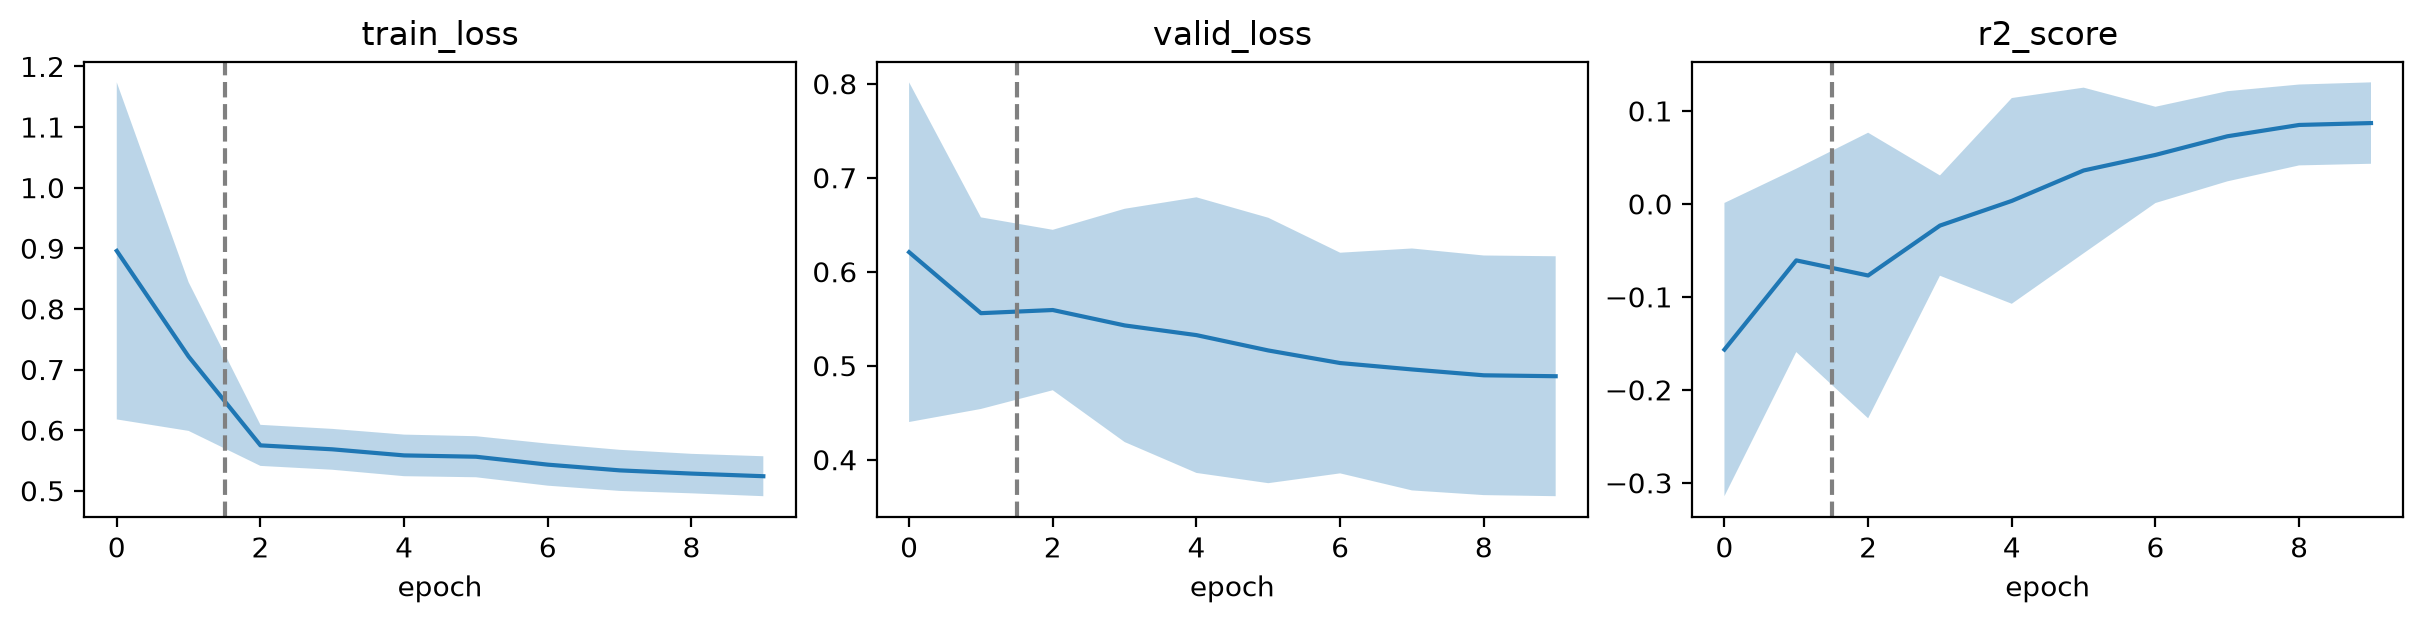

In [ ]:
plot_cv(res);